<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/5e_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autocodificador variacional
En esta libreta programaremos un autocodificador variacional (VAE) con redes densas y lo aplicaremos al conjunto de imágenes de dígitos escritos a mano MNIST.

In [1]:
import os

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import numpy as np

import torch as th
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import MNIST
from torch.nn import Sequential, Linear, LeakyReLU, Tanh
from torch.optim import Adam

from torch.utils.tensorboard import SummaryWriter

N_EPOCAS = 100
T_LOTE = 32
D_LATENTE = 50
SEED = 42
N_TRAB = os.cpu_count() or 1
LR = 1e-3
DC = th.device('cuda' if th.cuda.is_available() else 'cpu')

# Para reproducibilidad
np.random.seed(SEED)
th.manual_seed(SEED)

## Conjunto de datos
Descargamos los subconjuntos de entrenamiento y prueba de MNIST:

In [2]:
ent = MNIST(root = 'mnist',
            train = True,
            download = True)

prueba = MNIST(root = 'mnist',
               train = False,
               download = True)

Aplanamos cada imagen de $28 \times 28$ en un vector de 784 elementos y escalamos los valores de los píxeles de $[0, 255]$ a $[-1, 1]$.

In [3]:
H, W = ent.data.shape[1:]
D_ENTRADA = H * W

# Aplanamos imágenes en vectores
X_ent = ent.data.reshape(ent.data.shape[0], D_ENTRADA).float()
X_prueba = prueba.data.reshape(prueba.data.shape[0], D_ENTRADA).float()

# Escalamos valores a intervalo [-1, 1]
X_ent = (X_ent - 127.5) / 127.5
X_prueba = (X_prueba - 127.5) / 127.5

X_ent.shape, X_prueba.shape

(torch.Size([60000, 784]), torch.Size([10000, 784]))

Definimos la clase para cargar datos.

In [4]:
class MiDS(Dataset):
  def __init__(self,
               X: th.Tensor) -> None:
    self.x = X

  def __getitem__(self,
                  i: int) -> th.Tensor:
    return self.x[i]

  def __len__(self) -> int:
    return len(self.x)

Definimos una función para desplegar imágenes en una cuadrícula. Como los valores están en $[-1, 1]$, fijamos `vmin` y `vmax` para que `imshow` no reescale cada imagen por separado.

In [5]:
def visualiza_imagenes(xs: np.ndarray,
                       n_filas: int = 10,
                       n_columnas: int = 10,
                       t_celda: float = 1.0,
                       alto: int = 28,
                       ancho: int = 28) -> None:
  fig, axs = plt.subplots(nrows = n_filas,
                          ncols = n_columnas,
                          figsize = (t_celda * n_columnas, t_celda * n_filas),
                          squeeze = False,
                          gridspec_kw = {'wspace': 0.05, 'hspace': 0.05})

  for idx, ax in enumerate(axs.flat):
    ax.axis('off')
    if idx < len(xs):
      ax.imshow(xs[idx].reshape(alto, ancho),
                cmap = 'gray',
                vmin = -1,
                vmax = 1)
  plt.show()

Creamos nuestro cargador de datos y visualizamos algunas imágenes de un lote.

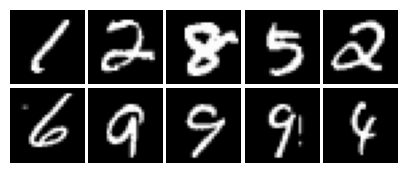

In [6]:
entds = MiDS(X_ent)
entdl = DataLoader(entds,
                   batch_size = T_LOTE,
                   shuffle = True,
                   drop_last = True,
                   persistent_workers = True,
                   prefetch_factor = 2,
                   num_workers = N_TRAB)

x = next(iter(entdl))
visualiza_imagenes(x[:10].numpy(), n_filas = 2, n_columnas = 5)

## Autocodificador variacional
El autocodificador variacional (VAE) está compuesto por un codificador y un decodificador. En esta libreta tanto el codificador como el decodificador serán redes densas.

### Codificador
Definimos nuestro codificador, que a partir de una imagen $\mathbf{x}$ produce la media $\boldsymbol{\mu}_{\mathbf{z}}$ y el logaritmo de la varianza $\log \boldsymbol{\sigma}_{\mathbf{z}}^2$ de la distribución posterior aproximada $Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x})$.

In [7]:
class Codificador(nn.Module):
  def __init__(self,
               d_ent: int,
               d_lat: int) -> None:
    super().__init__()

    self.densa_entrada = Sequential(Linear(d_ent, 400),
                                    LeakyReLU(),
                                    Linear(400, 150),
                                    LeakyReLU())
    self.densa_mu = Linear(150, d_lat)
    self.densa_logvar = Linear(150, d_lat)

  def forward(self,
              x: th.Tensor) -> tuple[th.Tensor, th.Tensor]:
    h = self.densa_entrada(x)
    mu = self.densa_mu(h)
    logvar = self.densa_logvar(h)

    return mu, logvar

### Decodificador
Nuestro decodificador toma un vector latente $\mathbf{z}$ y produce la reconstrucción de la imagen. Como las imágenes están en $[-1, 1]$, la última capa del decodificador usa una función de activación `Tanh`.

In [8]:
class Decodificador(nn.Module):
  def __init__(self,
               d_sal: int,
               d_lat: int) -> None:
    super().__init__()

    self.red_densa = Sequential(Linear(d_lat, 150),
                                LeakyReLU(),
                                Linear(150, 400),
                                LeakyReLU(),
                                Linear(400, d_sal),
                                Tanh())

  def forward(self,
              z: th.Tensor) -> th.Tensor:
    return self.red_densa(z)

### Clase completa
La clase del autocodificador variacional completo instancia el codificador y el decodificador. Para obtener la muestra de $\mathbf{z} \sim Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x})$ de forma que podamos propagar los gradientes hacia el codificador, se emplea el truco de la reparametrización

$$
\mathbf{z} = \boldsymbol{\mu}_{\mathbf{z}} + \boldsymbol{\sigma}_{\mathbf{z}} \odot \boldsymbol{\epsilon}, \quad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})
$$
donde $\boldsymbol{\sigma}_{\mathbf{z}} = \exp(\frac{1}{2} \log \boldsymbol{\sigma}_{\mathbf{z}}^2)$.

In [9]:
class VAE(nn.Module):
  def __init__(self,
               d_ent: int,
               d_lat: int) -> None:
    super().__init__()

    self.d_ent = d_ent
    self.d_lat = d_lat

    self.cod = Codificador(d_ent, d_lat)
    self.dec = Decodificador(d_ent, d_lat)

  def proyectar(self,
                x: th.Tensor) -> tuple[th.Tensor, th.Tensor, th.Tensor]:
    mu, logvar = self.cod(x)
    std = th.exp(0.5 * logvar)
    eps = th.randn_like(std)
    z = mu + eps * std
    return z, mu, logvar

  def forward(self,
              x: th.Tensor) -> tuple[th.Tensor, th.Tensor, th.Tensor]:
    z, mu, logvar = self.proyectar(x)
    xrec = self.dec(z)
    return xrec, mu, logvar

  @th.inference_mode()
  def genera_imagenes(self,
                      n_muestras: int) -> th.Tensor:
    disp = next(self.parameters()).device
    z = th.randn((n_muestras, self.d_lat), device = disp)
    return self.dec(z)

## Función de pérdida
Suponemos que el decodificador produce la media $\boldsymbol{\mu}_\mathbf{x}$ de una distribución gaussiana $P_{\boldsymbol{\theta}}(\mathbf{x} \vert \mathbf{z}) = \mathcal{N}(\boldsymbol{\mu}_\mathbf{x}, \sigma_{\mathbf{x}}^2 \mathbf{I})$ con varianza $\sigma_{\mathbf{x}}^2$ fija. Con esta suposición, el negativo de la cota inferior de la evidencia (ELBO) promediado sobre $N$ imágenes es

$$
-\mathcal{L}_{\boldsymbol{\theta}, \boldsymbol{\phi}}(\mathbf{X}) \approx \frac{1}{N} \sum_{i=1}^{N} \left[\frac{1}{2\sigma_{\mathbf{x}}^2} \Vert \mathbf{x}^{(i)} - \boldsymbol{\mu}_\mathbf{x}^{(i)} \Vert_2^2 + D_{KL}\left[Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x}^{(i)}) \Vert P(\mathbf{z})\right]\right] + \text{cte.}
$$

donde $\boldsymbol{\mu}_\mathbf{x}^{(i)}$ es la salida del decodificador para un vector $\mathbf{z}^{(i)}$ muestreado de $Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x}^{(i)})$ con el truco de la reparametrización. El primer término es el error de reconstrucción y el segundo es la divergencia KL entre $Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x})$ y la distribución a priori $P(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$, que tiene la forma cerrada

$$
D_{KL}\left[Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x}) \Vert P(\mathbf{z})\right] = \frac{1}{2} \sum_{j=1}^{d} \left(\mu_{z_j}^2 + \sigma_{z_j}^2 - \log \sigma_{z_j}^2 - 1\right)
$$

donde $\mu_{z_j}$ y $\sigma_{z_j}$ son las componentes de $\boldsymbol{\mu}_{\mathbf{z}}$ y $\boldsymbol{\sigma}_{\mathbf{z}}$ que produce el codificador y $d$ es la dimensionalidad de $\mathbf{z}$. En la práctica, $N$ es el tamaño del lote y fijamos $\sigma_{\mathbf{x}}^2 = \frac{1}{2}$, por lo que el error de reconstrucción es la suma de los errores cuadráticos sobre todos los píxeles.

In [10]:
class PerdidaVAE(nn.Module):
  def __init__(self) -> None:
    super().__init__()

    self.mse = nn.MSELoss(reduction = 'sum')

  def forward(self,
              xrec: th.Tensor,
              x: th.Tensor,
              mu: th.Tensor,
              logvar: th.Tensor) -> th.Tensor:

    n = x.shape[0]
    ec = self.mse(xrec, x) / n
    kl = 0.5 * th.sum(mu**2 + logvar.exp() - logvar - 1) / n
    return ec + kl

## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones.

### Registrar información para TensorBoard
Para guardar información que pueda visualizarse con TensorBoard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ejemplo, `add_scalar`, `add_image`, `add_histogram`, etc.).

In [11]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[str, np.ndarray]) -> None:
  for (m, v) in hist.items():
    writer.add_scalar(m, v[epoca], epoca)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida como instancia de `PerdidaVAE` (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* Una instancia de `Tensor` con el lote de entradas (`X`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

En cada paso de entrenamiento, el lote de imágenes se pasa por el autocodificador variacional para obtener las reconstrucciones, $\boldsymbol{\mu}_{\mathbf{z}}$ y $\log \boldsymbol{\sigma}_{\mathbf{z}}^2$, se calcula la pérdida, se obtienen los gradientes y se actualizan los parámetros. Si el dispositivo es una GPU que soporta `bfloat16` de forma nativa, usamos precisión mixta.

In [12]:
def paso_ent(modelo: nn.Module,
             fp: PerdidaVAE,
             opt: th.optim.Optimizer,
             X: th.Tensor,
             disp: str | th.device) -> th.Tensor:
  # Ponemos los gradientes asociados a los parámetros
  # a actualizar en cero
  opt.zero_grad()
  tipo_disp = th.device(disp).type

  # Se habilita precisión mixta solo si el dispositivo es cuda y
  # soporta bfloat16 de forma nativa (capacidad de cómputo >= 8.0)
  usa_amp = (tipo_disp == 'cuda' and th.cuda.get_device_capability(disp)[0] >= 8)

  with th.autocast(device_type = tipo_disp,
                   dtype = th.bfloat16, enabled = usa_amp):
    # Propagamos las entradas para obtener las reconstrucciones
    Xrec, mu, logvar = modelo(X)

    # Calculamos la pérdida
    perdida = fp(Xrec, X, mu, logvar)

  # Obtenemos los gradientes
  perdida.backward()

  # Actualizamos todos los parámetros del modelo
  opt.step()

  return perdida.detach()

### Época de entrenamiento
Definimos una función para realizar una época de entrenamiento, que llamaremos `entrena_epoca`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos del subconjunto de entrenamiento (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

In [13]:
def entrena_epoca(modelo: nn.Module,
                  fp: PerdidaVAE,
                  opt: th.optim.Optimizer,
                  dl: DataLoader,
                  disp: th.device | str = 'cuda') -> float:
  n_total = 0
  suma_perdida = 0.0

  modelo.train()
  for X in dl:
    X = X.to(disp)

    perdida_paso = paso_ent(modelo,
                            fp,
                            opt,
                            X,
                            disp)

    n_lote = X.shape[0]
    n_total += n_lote

    # La pérdida es el promedio sobre las imágenes del lote
    suma_perdida += perdida_paso * n_lote

  perdida_epoca = (suma_perdida / n_total).item()
  return perdida_epoca

### Ciclo principal
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
* El cargador de datos (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).
* El número de épocas de entrenamiento (`n_epocas`).
* La ruta al directorio donde se guardará la información para TensorBoard (`tbdir`).

In [14]:
def entrena(modelo: nn.Module,
            fp: PerdidaVAE,
            opt: th.optim.Optimizer,
            dl: DataLoader,
            disp: th.device | str = 'cuda',
            n_epocas: int = 30,
            tbdir: str = 'runs/') -> tuple[nn.Module, dict[str, np.ndarray]]:

  hist = {
    'perdida': np.zeros(n_epocas)
    }

  tbwriter = SummaryWriter(tbdir)

  modelo.to(disp)
  for e in tqdm(range(n_epocas)):
    hist['perdida'][e] = entrena_epoca(modelo,
                                       fp,
                                       opt,
                                       dl,
                                       disp)

    registra_info_tboard(tbwriter, e, hist)

    print(f'Época {e}: '
          f'Pérdida = {hist["perdida"][e]:.3f}')

  tbwriter.close()

  return modelo, hist

## Entrenamiento
Instanciamos nuestra clase de autocodificador variacional, la movemos a la GPU si está disponible, instanciamos el optimizador y entrenamos el modelo.

In [15]:
vae = VAE(D_ENTRADA, D_LATENTE)
vae.to(DC)

fp = PerdidaVAE()

opt = Adam(vae.parameters(), lr = LR)

vae, hist = entrena(vae,
                    fp,
                    opt,
                    entdl,
                    disp = DC,
                    n_epocas = N_EPOCAS)

  0%|          | 0/100 [00:00<?, ?it/s]

Época 0: Pérdida = 119.972
Época 1: Pérdida = 84.987
Época 2: Pérdida = 78.156
Época 3: Pérdida = 74.411
Época 4: Pérdida = 72.388
Época 5: Pérdida = 71.035
Época 6: Pérdida = 70.066
Época 7: Pérdida = 69.372
Época 8: Pérdida = 68.725
Época 9: Pérdida = 68.130
Época 10: Pérdida = 67.675
Época 11: Pérdida = 67.162
Época 12: Pérdida = 66.850
Época 13: Pérdida = 66.588
Época 14: Pérdida = 66.216
Época 15: Pérdida = 66.047
Época 16: Pérdida = 65.684
Época 17: Pérdida = 65.501
Época 18: Pérdida = 65.309
Época 19: Pérdida = 65.144
Época 20: Pérdida = 65.000
Época 21: Pérdida = 64.828
Época 22: Pérdida = 64.645
Época 23: Pérdida = 64.526
Época 24: Pérdida = 64.347
Época 25: Pérdida = 64.233
Época 26: Pérdida = 64.130
Época 27: Pérdida = 63.972
Época 28: Pérdida = 63.789
Época 29: Pérdida = 63.683
Época 30: Pérdida = 63.633
Época 31: Pérdida = 63.539
Época 32: Pérdida = 63.371
Época 33: Pérdida = 63.278
Época 34: Pérdida = 63.240
Época 35: Pérdida = 63.177
Época 36: Pérdida = 62.995
Época 37: 

Graficamos las pérdidas por época.

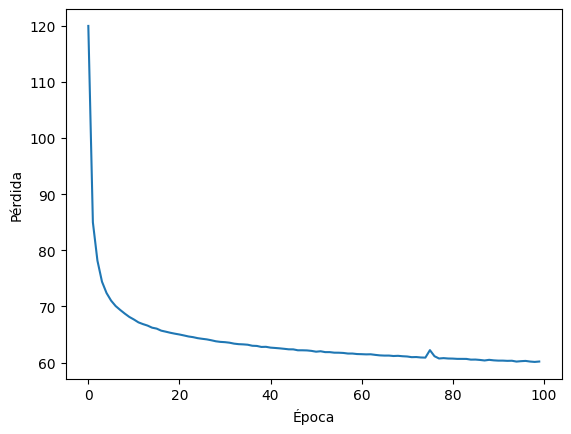

In [16]:
plt.plot(hist['perdida'])
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.show()

## Reconstrucción de imágenes de entrenamiento y prueba
Pasamos el modelo a la CPU y lo ponemos en modo de evaluación.

In [17]:
vae = vae.to('cpu')
vae.eval()

VAE(
  (cod): Codificador(
    (densa_entrada): Sequential(
      (0): Linear(in_features=784, out_features=400, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=400, out_features=150, bias=True)
      (3): LeakyReLU(negative_slope=0.01)
    )
    (densa_mu): Linear(in_features=150, out_features=50, bias=True)
    (densa_logvar): Linear(in_features=150, out_features=50, bias=True)
  )
  (dec): Decodificador(
    (red_densa): Sequential(
      (0): Linear(in_features=50, out_features=150, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=150, out_features=400, bias=True)
      (3): LeakyReLU(negative_slope=0.01)
      (4): Linear(in_features=400, out_features=784, bias=True)
      (5): Tanh()
    )
  )
)

Para obtener reconstrucciones deterministas, decodificamos la media $\boldsymbol{\mu}_{\mathbf{z}}$ en lugar de una muestra de $Q_{\boldsymbol{\phi}}(\mathbf{z} \vert \mathbf{x})$.

Visualizamos algunas imágenes de entrenamiento (filas impares) y sus reconstrucciones (filas pares).

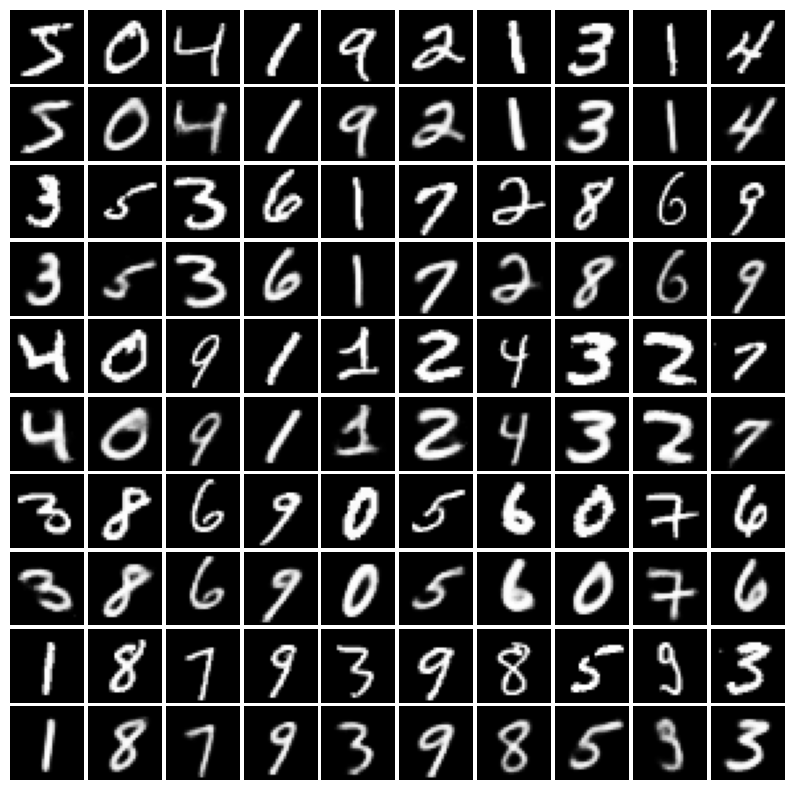

In [18]:
@th.inference_mode()
def reconstruye(modelo: nn.Module,
                x: th.Tensor) -> th.Tensor:
  mu, _ = modelo.cod(x)
  return modelo.dec(mu)

X = X_ent[:50]
Xrec = reconstruye(vae, X)
pares = th.cat([th.cat([X[i:i + 10], Xrec[i:i + 10]]) for i in range(0, 50, 10)])
visualiza_imagenes(pares.numpy(),
                   n_filas = 10,
                   n_columnas = 10,
                   t_celda = 1.0,
                   alto = H,
                   ancho = W)

Hacemos lo mismo con imágenes de prueba.

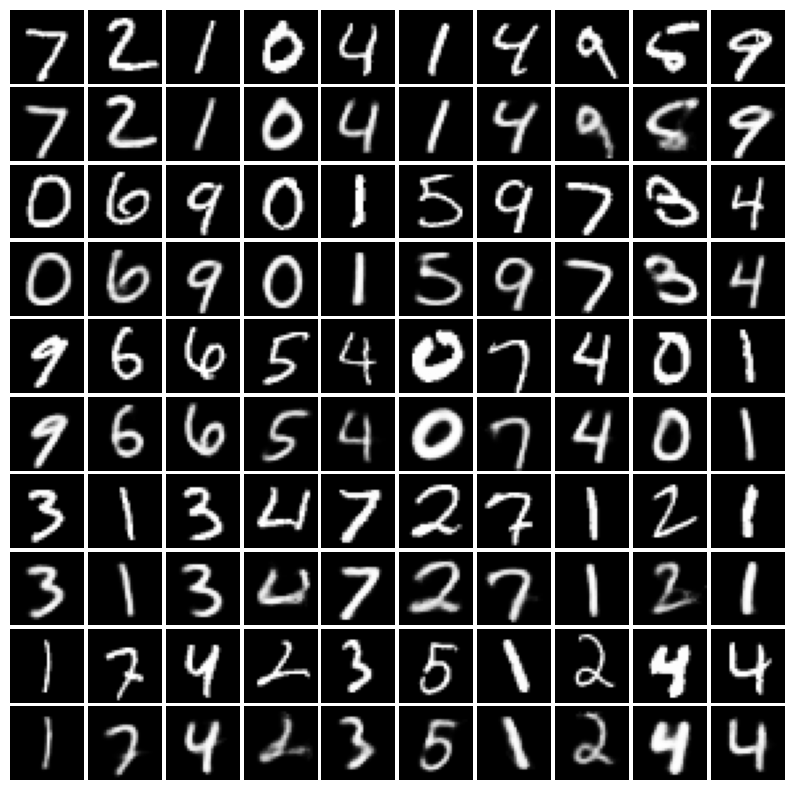

In [19]:
X = X_prueba[:50]
Xrec = reconstruye(vae, X)
pares = th.cat([th.cat([X[i:i + 10], Xrec[i:i + 10]]) for i in range(0, 50, 10)])

visualiza_imagenes(pares.numpy(),
                   n_filas = 10,
                   n_columnas = 10,
                   t_celda = 1.0,
                   alto = H,
                   ancho = W)

## Generación de muestras aleatorias
Muestreamos vectores latentes $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ y generamos imágenes a partir de estos.

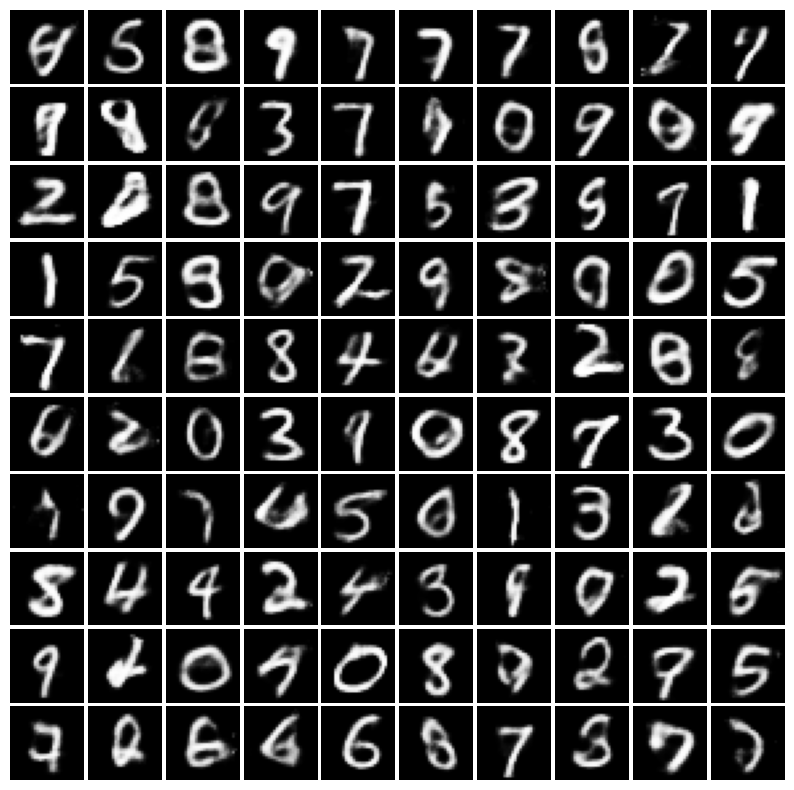

In [20]:
Xgen = vae.genera_imagenes(100)

visualiza_imagenes(Xgen.numpy(),
                   n_filas = 10,
                   n_columnas = 10,
                   t_celda = 1.0,
                   alto = H,
                   ancho = W)

## Interpolación de dos vectores
Obtenemos las medias latentes de todas las imágenes de prueba.

In [21]:
with th.inference_mode():
  mu_prueba, _ = vae.cod(X_prueba)

Tomamos dos imágenes de prueba, interpolamos linealmente entre sus medias latentes $\boldsymbol{\mu}_{\mathbf{z}}^{(1)}$ y $\boldsymbol{\mu}_{\mathbf{z}}^{(2)}$ (calculamos $(1 - \alpha) \boldsymbol{\mu}_{\mathbf{z}}^{(1)} + \alpha \boldsymbol{\mu}_{\mathbf{z}}^{(2)}$ para distintos valores de $\alpha \in [0, 1]$) y generamos las imágenes de los vectores interpolados.

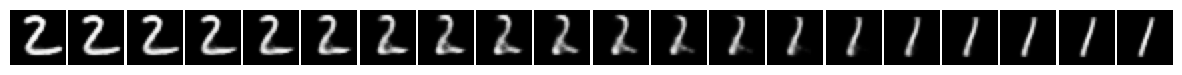

In [22]:
i1, i2 = 1, 2
alfas = th.linspace(0, 1, steps = 20)
zs = th.stack([(1 - a) * mu_prueba[i1] + a * mu_prueba[i2] for a in alfas])

with th.inference_mode():
  xinter = vae.dec(zs)

visualiza_imagenes(xinter.numpy(),
                   n_filas = 1,
                   n_columnas = 20,
                   t_celda = 0.75,
                   alto = H,
                   ancho = W)

## Aritmética de vectores latentes
Calculamos el vector latente medio de cada dígito. Al vector latente de una imagen de un 3 le restamos el vector medio del dígito 3 y le sumamos el vector medio de otro dígito.

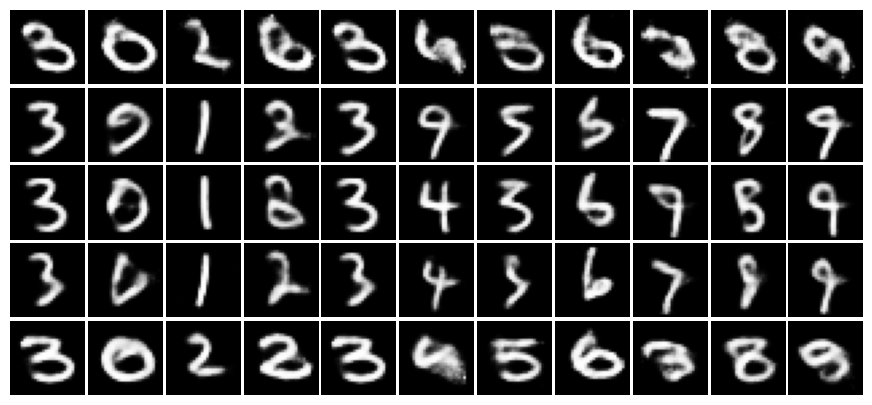

In [23]:
medias = th.stack([mu_prueba[prueba.targets == k].mean(dim = 0) for k in range(10)])

origen = 3
idx = th.where(prueba.targets == origen)[0][:5]
a = mu_prueba[idx]

with th.inference_mode():
  filas = [vae.dec(a)]
  for k in range(10):
    filas.append(vae.dec(a - medias[origen] + medias[k]))

# cada fila corresponde a una imagen de un 3: en la primera columna su
# reconstrucción y en las siguientes el resultado de cambiarla a los dígitos 0 a 9
xs = th.stack(filas).transpose(0, 1)
visualiza_imagenes(xs.reshape(-1, D_ENTRADA).numpy(),
                   n_filas = 5,
                   n_columnas = 11,
                   t_celda = 1.0,
                   alto = H,
                   ancho = W)